# Practical 5 — Quick Sort: Deterministic and Randomised Variants

**Subject:** Design and Analysis of Algorithms (410241)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Write a program for the analysis of **Quick Sort** using deterministic and
randomised variants, and compare their performance on different kinds of
input.

## 2. Problem statement

Implement Quick Sort with:

1. a **deterministic pivot** (the last element), and
2. a **randomised pivot** (an element chosen uniformly at random).

Measure the running time and the number of comparisons/swaps for random,
sorted, reverse-sorted and duplicate-heavy inputs.

## 3. Objectives

- Understand the divide-and-conquer structure of Quick Sort.
- Understand how pivot selection affects the best, average and worst cases.
- Measure the effect of adversarial input on a deterministic pivot.
- Verify that both variants sort correctly.

## 4. Theory

### 4.1 Divide and conquer

```text
QUICKSORT(A, low, high)
    if low < high
        p = PARTITION(A, low, high)
        QUICKSORT(A, low, p - 1)
        QUICKSORT(A, p + 1, high)
```

`PARTITION` rearranges the array so that:

- elements to the left of the pivot are $\le$ the pivot,
- elements to the right are $>$ the pivot,
- the pivot is in its final sorted position.

This notebook uses **Lomuto partitioning**, which scans the range once and
places the pivot at the end.

### 4.2 Complexity

| Case | Recurrence | Time | Example |
|---|---|---|---|
| Best | $T(n)=2T(n/2)+O(n)$ | $O(n\log n)$ | Pivot near the median |
| Average | random pivots | $O(n\log n)$ | Random input |
| Worst | $T(n)=T(n-1)+O(n)$ | $O(n^2)$ | Already sorted input with first/last pivot |

The recursion stack uses $O(\log n)$ space on average and $O(n)$ in the worst
case. Quick Sort is **in-place** (apart from the recursion stack) and is not
stable.

### 4.3 Deterministic vs randomised

A deterministic pivot always chooses the same position (here, the last
element). An adversary can therefore construct an input that forces the worst
case: sorted or reverse-sorted data makes every partition extremely
unbalanced.

A randomised pivot chooses the pivot uniformly at random. No fixed input can
force the worst case; the expected running time is $O(n\log n)$ for any input.
The worst case is still $O(n^2)$, but its probability is negligible.

> Randomised Quick Sort is a **Las Vegas** algorithm: the result is always
> correct, only the running time is random.

In [1]:
import random
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# The deterministic version can recurse N levels deep on sorted input.
sys.setrecursionlimit(100_000)

In [2]:
def quicksort_deterministic(values):
    """Quick Sort with the last element as pivot.

    Returns (sorted_list, comparisons, swaps).
    """
    array = list(values)
    comparisons = 0
    swaps = 0

    def partition(low, high):
        nonlocal comparisons, swaps
        pivot = array[high]
        boundary = low - 1

        for index in range(low, high):
            comparisons += 1
            if array[index] <= pivot:
                boundary += 1
                if boundary != index:
                    array[boundary], array[index] = array[index], array[boundary]
                    swaps += 1

        boundary += 1
        if boundary != high:
            array[boundary], array[high] = array[high], array[boundary]
            swaps += 1
        return boundary

    def sort(low, high):
        if low < high:
            pivot_index = partition(low, high)
            sort(low, pivot_index - 1)
            sort(pivot_index + 1, high)

    sort(0, len(array) - 1)
    return array, comparisons, swaps


def quicksort_randomised(values, seed=None):
    """Quick Sort with a uniformly random pivot.

    Returns (sorted_list, comparisons, swaps).
    """
    array = list(values)
    rng = random.Random(seed)
    comparisons = 0
    swaps = 0

    def partition(low, high):
        nonlocal comparisons, swaps
        # Choose a random pivot and move it to the end.
        pivot_index = rng.randint(low, high)
        if pivot_index != high:
            array[pivot_index], array[high] = array[high], array[pivot_index]
            swaps += 1

        pivot = array[high]
        boundary = low - 1
        for index in range(low, high):
            comparisons += 1
            if array[index] <= pivot:
                boundary += 1
                if boundary != index:
                    array[boundary], array[index] = array[index], array[boundary]
                    swaps += 1

        boundary += 1
        if boundary != high:
            array[boundary], array[high] = array[high], array[boundary]
            swaps += 1
        return boundary

    def sort(low, high):
        if low < high:
            pivot_index = partition(low, high)
            sort(low, pivot_index - 1)
            sort(pivot_index + 1, high)

    sort(0, len(array) - 1)
    return array, comparisons, swaps

In [3]:
# Correctness tests on small and medium arrays.
test_arrays = [
    [],
    [1],
    [2, 1],
    [3, 3, 3, 3],
    [5, 1, 4, 2, 8, 0, 2],
    list(range(20)),
    list(range(20, 0, -1)),
    [random.Random(1).randint(-50, 50) for _ in range(100)],
]

for values in test_arrays:
    expected = sorted(values)
    det_result, det_comparisons, det_swaps = quicksort_deterministic(values)
    rand_result, rand_comparisons, rand_swaps = quicksort_randomised(values, seed=7)
    assert det_result == expected, (values, det_result, expected)
    assert rand_result == expected, (values, rand_result, expected)

print("All correctness tests passed ✓")
print("Example: [5, 1, 4, 2, 8, 0, 2] ->", quicksort_deterministic([5, 1, 4, 2, 8, 0, 2])[0])

All correctness tests passed ✓
Example: [5, 1, 4, 2, 8, 0, 2] -> [0, 1, 2, 2, 4, 5, 8]


In [4]:
# Compare deterministic and randomised pivots on one sorted array.
sorted_input = list(range(15))
det_sorted, det_comparisons, _ = quicksort_deterministic(sorted_input)
rand_sorted, rand_comparisons, _ = quicksort_randomised(sorted_input, seed=42)

print("Sorted input of length 15")
print("Deterministic comparisons :", det_comparisons)
print("Randomised comparisons    :", rand_comparisons)
print("Both sorted correctly     :", det_sorted == rand_sorted == sorted_input)

Sorted input of length 15
Deterministic comparisons : 105
Randomised comparisons    : 46
Both sorted correctly     : True


On sorted input, the deterministic last-element pivot is always the maximum.
The partition therefore puts all other elements to the left and splits off only
one element, giving the recurrence $T(n)=T(n-1)+O(n)$ and $O(n^2)$ comparisons.
The randomised pivot usually lands somewhere in the middle, so the recursion
stays balanced.

In [5]:
# Build the four input families used in the benchmark.
def make_inputs(size, seed=123):
    """Return a dictionary of input arrays with the same length."""
    rng = random.Random(seed)
    random_values = [rng.randint(0, 10_000) for _ in range(size)]
    return {
        "random": random_values,
        "sorted": list(range(size)),
        "reverse sorted": list(range(size, 0, -1)),
        "all equal": [7] * size,
    }


def median(values):
    ordered = sorted(values)
    return ordered[len(ordered) // 2]


sizes = [100, 250, 500, 1_000, 1_500, 2_000]
repeats = 3
records = []

for size in sizes:
    inputs = make_inputs(size)
    for input_name, values in inputs.items():
        for algorithm_name, algorithm in [
            ("deterministic", quicksort_deterministic),
            ("randomised", quicksort_randomised),
        ]:
            times = []
            comparisons = []
            swaps = []
            for repeat in range(repeats):
                start = perf_counter()
                if algorithm_name == "deterministic":
                    result, comp, swp = algorithm(values)
                else:
                    result, comp, swp = algorithm(values, seed=1000 + repeat)
                times.append(perf_counter() - start)
                comparisons.append(comp)
                swaps.append(swp)
                assert result == sorted(values)

            records.append(
                {
                    "algorithm": algorithm_name,
                    "input": input_name,
                    "n": size,
                    "time (s)": median(times),
                    "comparisons": int(median(comparisons)),
                    "swaps": int(median(swaps)),
                }
            )

results = pd.DataFrame(records)
results.head(12)

,algorithm,input,n,time (s),comparisons,swaps
0,deterministic,random,100,0.000080,618,303
1,randomised,random,100,0.000105,621,351
2,deterministic,sorted,100,0.000373,4950,0
3,randomised,sorted,100,0.000089,711,98
4,deterministic,reverse sorted,100,0.000329,4950,50
5,randomised,reverse sorted,100,0.000100,666,298
6,deterministic,all equal,100,0.000389,4950,0
7,randomised,all equal,100,0.000429,4950,95
8,deterministic,random,250,0.000287,1907,876
9,randomised,random,250,0.000405,2024,1017


In [6]:
# A compact view at n = 1000.
results[results["n"] == 1_000].pivot(
    index="input", columns="algorithm", values=["time (s)", "comparisons"]
)

time (s)              comparisons           
algorithm      deterministic randomised deterministic randomised
input                                                           
all equal           0.054341   0.053484      499500.0   499500.0
random              0.001718   0.002094       10703.0    10777.0
reverse sorted      0.050201   0.002114      499500.0    10746.0
sorted              0.053774   0.001644      499500.0    10666.0

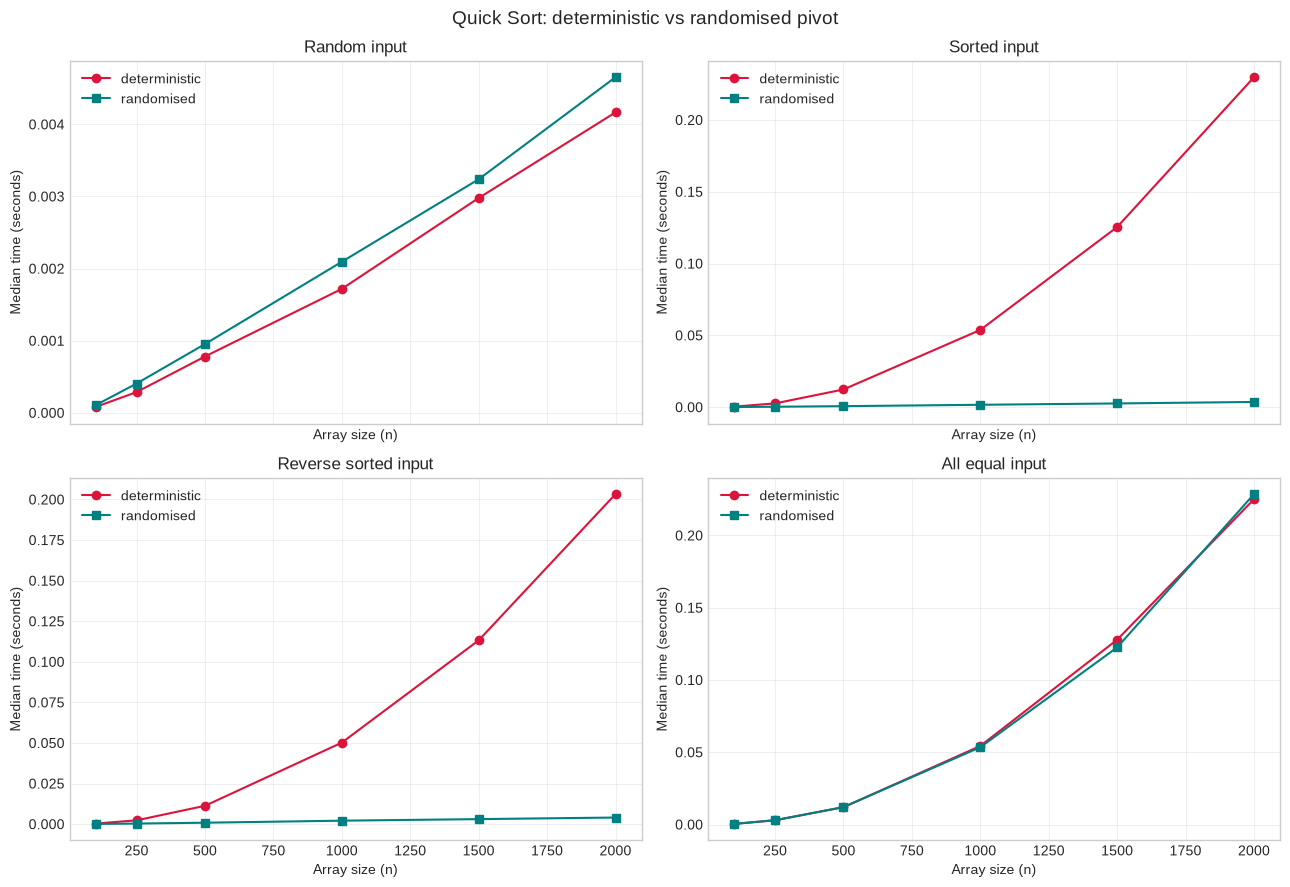

In [7]:
# Plot the running time for each input family.
figure, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
input_names = ["random", "sorted", "reverse sorted", "all equal"]

for axis, input_name in zip(axes.flat, input_names):
    subset = results[results["input"] == input_name]
    for algorithm_name, colour, marker in [
        ("deterministic", "crimson", "o"),
        ("randomised", "teal", "s"),
    ]:
        data = subset[subset["algorithm"] == algorithm_name].sort_values("n")
        axis.plot(
            data["n"],
            data["time (s)"],
            marker=marker,
            color=colour,
            label=algorithm_name,
        )
    axis.set_title(f"{input_name.capitalize()} input")
    axis.set_xlabel("Array size (n)")
    axis.set_ylabel("Median time (seconds)")
    axis.grid(alpha=0.3)
    axis.legend()

figure.suptitle("Quick Sort: deterministic vs randomised pivot", fontsize=14)
plt.tight_layout()
plt.show()

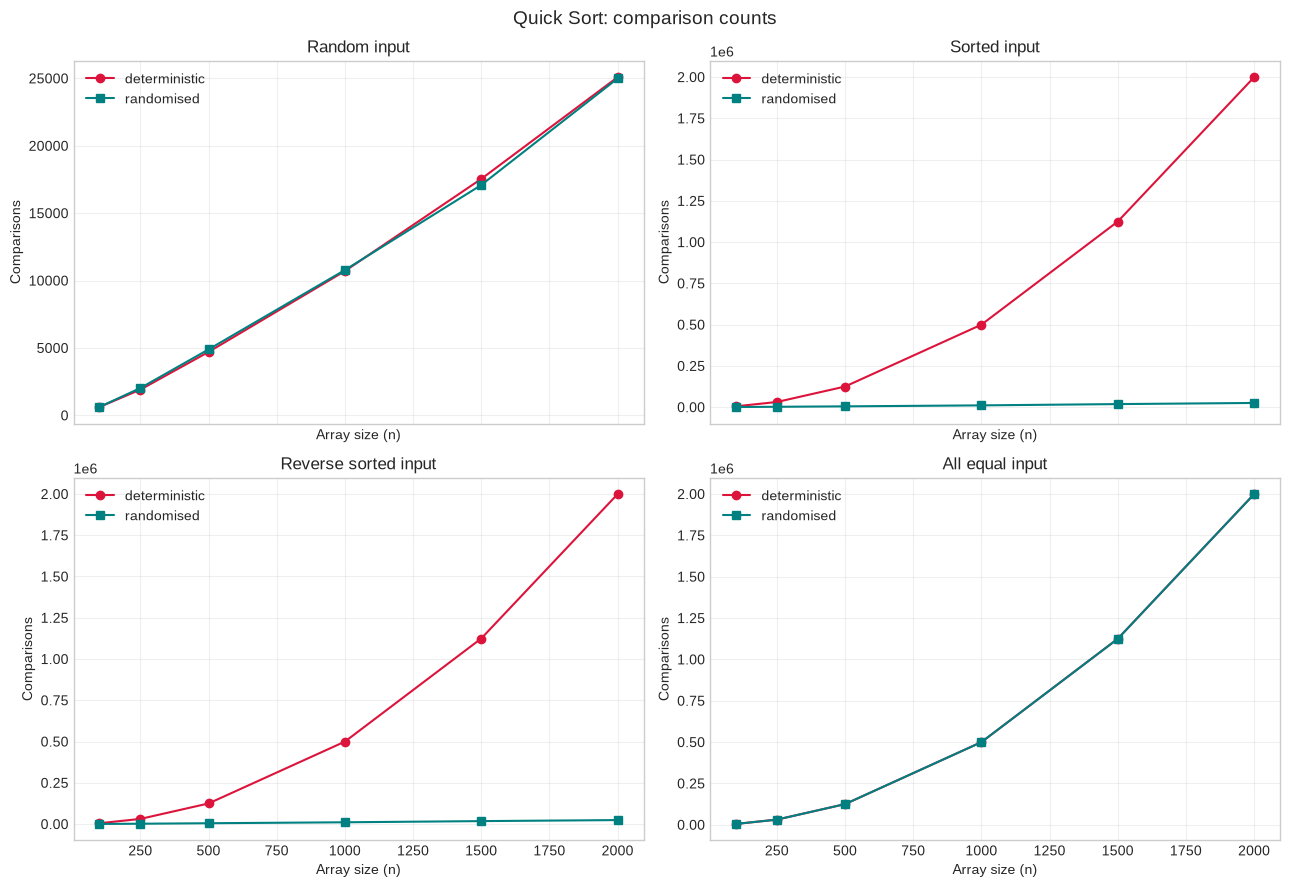

In [8]:
# Plot the number of comparisons; this shows the O(n^2) blow-up more clearly.
figure, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

for axis, input_name in zip(axes.flat, input_names):
    subset = results[results["input"] == input_name]
    for algorithm_name, colour, marker in [
        ("deterministic", "crimson", "o"),
        ("randomised", "teal", "s"),
    ]:
        data = subset[subset["algorithm"] == algorithm_name].sort_values("n")
        axis.plot(
            data["n"],
            data["comparisons"],
            marker=marker,
            color=colour,
            label=algorithm_name,
        )
    axis.set_title(f"{input_name.capitalize()} input")
    axis.set_xlabel("Array size (n)")
    axis.set_ylabel("Comparisons")
    axis.grid(alpha=0.3)
    axis.legend()

figure.suptitle("Quick Sort: comparison counts", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - DAA Practical 5 (Quick Sort)")
print("=" * 78)
print(
    "Both variants sort correctly, so the interesting output is the cost. The\n"
    "comparison counts expose the algorithmic behaviour more clearly than the\n"
    "wall-clock times, which also include Python overhead and scheduling noise."
)

print("\n1. CORRECTNESS TESTS")
print("-" * 78)
print("All small/medium test arrays sorted correctly: True")
print("Example [5, 1, 4, 2, 8, 0, 2] ->",
      quicksort_deterministic([5, 1, 4, 2, 8, 0, 2])[0])
print("A sorting algorithm is only useful if it is correct; the timing results")
print("below are meaningful only after these assertions pass.")

print("\n2. THE SORTED-INPUT WARNING")
print("-" * 78)
print(f"Sorted input of length 15: deterministic={det_comparisons} comparisons, "
      f"randomised={rand_comparisons} comparisons")
print("With the last element as pivot, sorted input gives the maximum as pivot")
print("at every level. The partition removes only one element, so the work is")
print("1 + 2 + ... + (n-1) = n(n-1)/2 comparisons: O(n^2).")

print("\n3. BENCHMARK AT n = 1000")
print("-" * 78)
at_1000 = results[results["n"] == 1_000]
for input_name in input_names:
    det = at_1000[
        (at_1000["input"] == input_name) & (at_1000["algorithm"] == "deterministic")
    ].iloc[0]
    rand = at_1000[
        (at_1000["input"] == input_name) & (at_1000["algorithm"] == "randomised")
    ].iloc[0]
    det_comparisons_1000 = int(det["comparisons"])
    rand_comparisons_1000 = int(rand["comparisons"])
    ratio = det_comparisons_1000 / max(rand_comparisons_1000, 1)
    print(
        f"  {input_name:14s}: deterministic {det_comparisons_1000:7,d} comparisons "
        f"({float(det['time (s)']):.6f} s)"
    )
    print(
        f"  {'':14s}  randomised    {rand_comparisons_1000:7,d} comparisons "
        f"({float(rand['time (s)']):.6f} s), det/rand={ratio:.2f}x"
    )
print("Random input is already close to balanced, so the deterministic pivot")
print("performs reasonably. Sorted and reverse-sorted inputs are adversarial")
print("for the last-element pivot: the deterministic count is close to")
print("n(n-1)/2, while the randomised pivot usually finds a more balanced split")
print("and stays near O(n log n). All-equal input is different: both variants")
print("are unbalanced with Lomuto's `<=` rule, as the next section shows.")

largest_n = int(results["n"].max())
largest = results[results["n"] == largest_n]
det_sorted_large = largest[
    (largest["input"] == "sorted") & (largest["algorithm"] == "deterministic")
].iloc[0]
rand_sorted_large = largest[
    (largest["input"] == "sorted") & (largest["algorithm"] == "randomised")
].iloc[0]
print(f"\nAt n={largest_n}, sorted input:")
print(
    f"  deterministic: {int(det_sorted_large['comparisons']):,} comparisons, "
    f"{float(det_sorted_large['time (s)']):.6f} s"
)
print(
    f"  randomised   : {int(rand_sorted_large['comparisons']):,} comparisons, "
    f"{float(rand_sorted_large['time (s)']):.6f} s"
)
print("The deterministic comparison count grows quadratically; the randomised")
print("count grows much more slowly. Wall-clock times can be noisy for small")
print("arrays, so use the comparison counts to see the asymptotic difference.")

print("\n4. ALL-EQUAL INPUT")
print("-" * 78)
equal_det = at_1000[
    (at_1000["input"] == "all equal") & (at_1000["algorithm"] == "deterministic")
].iloc[0]
equal_rand = at_1000[
    (at_1000["input"] == "all equal") & (at_1000["algorithm"] == "randomised")
].iloc[0]
print(f"Deterministic comparisons: {int(equal_det['comparisons']):,}")
print(f"Randomised comparisons   : {int(equal_rand['comparisons']):,}")
print("Lomuto's `<=` sends every equal element to the left, so duplicates also")
print("produce unbalanced partitions. A three-way partition would separate")
print("less-than, equal and greater-than groups and handle this input in")
print("O(n log n) time.")

print("\n5. COMPLEXITY TAKEAWAY")
print("-" * 78)
print("Deterministic last pivot:")
print("  best/avg O(n log n), worst O(n^2) on sorted/reverse-sorted input")
print("Randomised pivot:")
print("  expected O(n log n) for every input; worst O(n^2) with tiny probability")
print("Both are in-place apart from the recursion stack: O(log n) average and")
print("O(n) worst-case stack depth. Randomisation does not make the algorithm")
print("always linear; it removes the fixed pattern that an adversary can exploit.")

DETAILED OUTPUT EXPLANATION - DAA Practical 5 (Quick Sort)
Both variants sort correctly, so the interesting output is the cost. The
comparison counts expose the algorithmic behaviour more clearly than the
wall-clock times, which also include Python overhead and scheduling noise.

1. CORRECTNESS TESTS
------------------------------------------------------------------------------
All small/medium test arrays sorted correctly: True
Example [5, 1, 4, 2, 8, 0, 2] -> [0, 1, 2, 2, 4, 5, 8]
A sorting algorithm is only useful if it is correct; the timing results
below are meaningful only after these assertions pass.

2. THE SORTED-INPUT WARNING
------------------------------------------------------------------------------
Sorted input of length 15: deterministic=105 comparisons, randomised=46 comparisons
With the last element as pivot, sorted input gives the maximum as pivot
at every level. The partition removes only one element, so the work is
1 + 2 + ... + (n-1) = n(n-1)/2 comparisons: O(n^2)

### Observations

1. On **random input**, both variants are close to $O(n\log n)$. The
   deterministic pivot is usually acceptable because a random array is
   unlikely to be perfectly ordered.
2. On **sorted** and **reverse-sorted** input, the deterministic last-element
   pivot is consistently the smallest or largest element. Every partition is
   maximally unbalanced, so the comparison count grows quadratically and the
   recursion depth becomes $n$.
3. On **all-equal** input, Lomuto partitioning with `<=` also produces an
   unbalanced split. A three-way partition (Dutch national flag) would handle
   duplicates in $O(n)$ per level and give $O(n\log n)$ on this input.
4. The randomised pivot removes the fixed adversarial pattern. Its expected
   time is $O(n\log n)$ regardless of the initial order, and its worst case
   is extremely unlikely.
5. The number of swaps is not the whole story: even when no swap is needed
   (sorted input), the algorithm still performs $O(n^2)$ comparisons.

### Complexity analysis

| Variant | Best | Average | Worst | Extra space |
|---|---|---|---|---|
| Deterministic (last pivot) | $O(n\log n)$ | $O(n\log n)$ | $O(n^2)$ on sorted/reverse input | $O(\log n)$ average, $O(n)$ worst |
| Randomised | $O(n\log n)$ | $O(n\log n)$ expected | $O(n^2)$ with tiny probability | $O(\log n)$ expected, $O(n)$ worst |

## 5. Conclusion

We implemented deterministic and randomised Quick Sort and verified both
against Python's built-in sort. The experiment shows that pivot selection has
a dramatic effect on performance: a fixed last-element pivot degrades to
$O(n^2)$ on already sorted or reverse-sorted data, while randomisation gives
$O(n\log n)$ expected performance on every input family. The results match the
theoretical analysis of best, average and worst cases.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is the principle of Quick Sort? | Divide and conquer: partition around a pivot, then sort the two sub-arrays recursively. |
| What is the best-case time? | $O(n\log n)$ when the pivot splits the array into two equal halves. |
| What is the worst-case time? | $O(n^2)$ when the pivot is always the smallest or largest element. |
| Why does sorted input hurt the deterministic version? | The last element is always the maximum, so every partition is unbalanced. |
| How does randomisation help? | It prevents a fixed input from forcing the worst case; the expected time is $O(n\log n)$. |
| Is Quick Sort stable? | No; the partition can change the relative order of equal elements. |
| Is Quick Sort in-place? | Yes, apart from the recursion stack. |
| What is Lomuto partitioning? | A single-scan partition that keeps a boundary of elements $\le$ the pivot and places the pivot at the end. |
| How can duplicates be handled better? | Use three-way partitioning (less than, equal, greater), which gives $O(n\log n)$ for all-equal input. |